### Closed-system quantum annealing for weighted Max-Cut

We consider three spins with edge weights
$w_{01}=1$, $w_{12}=2$, and $w_{02}=3$.
A bitstring $\mathbf{b}=(b_0,b_1,b_2)$ represents a partition,
with $z_i=(-1)^{b_i}$. Its cut value is

$$
C(\mathbf{b})=\sum_{(i,j)}\frac{w_{ij}}{2}(1-z_i z_j).
$$

To maximize the cut, we minimize the problem Hamiltonian

$$
H_P=-\widehat{C}
=-\frac{1}{2}(I-Z_0Z_1)
-(I-Z_1Z_2)
-\frac{3}{2}(I-Z_0Z_2),
$$

where $X_i$ and $Z_i$ are Pauli operators acting on spin $i$.

The driver Hamiltonian and its initial ground state are

$$
H_D=-\sum_{i=0}^{2}X_i,
\qquad
|\psi(0)\rangle=|+\rangle^{\otimes 3},
\qquad
|+\rangle=\frac{|0\rangle+|1\rangle}{\sqrt{2}}.
$$

Using $\hbar=1$ and a fixed energy unit, we apply a linear ramp:

$$
H(t)=\left(1-\frac{t}{T}\right)H_D+\frac{t}{T}H_P,
\qquad 0\leq t\leq T.
$$

**Algorithm**

1. Construct $H_D$, $H_P$, and $|\psi(0)\rangle$.
2. Integrate the closed-system Schrödinger equation:

$$
\frac{d|\psi(t)\rangle}{dt}=-iH(t)|\psi(t)\rangle.
$$

3. Calculate the configuration probabilities and mean cut:

$$
P_{\mathbf{b}}(t)=|\langle\mathbf{b}|\psi(t)\rangle|^2,
\qquad
\langle C\rangle(t)=
\langle\psi(t)|\widehat{C}|\psi(t)\rangle.
$$

4. Evaluate the probability of obtaining an optimal cut:

$$
P_{\mathrm{opt}}(t)=P_{001}(t)+P_{110}(t).
$$

For this instance, $C_{\max}=5$. The initial checks are
$P_{\mathrm{opt}}(0)=1/4$ and $\langle C\rangle(0)=3$.
Repeat for different durations $T$ to assess final performance,
while verifying $\langle\psi(t)|\psi(t)\rangle\approx1$.

Classical verification
  000: cut = 0.0
  001: cut = 5.0
  010: cut = 3.0
  011: cut = 4.0
  100: cut = 4.0
  101: cut = 3.0
  110: cut = 5.0
  111: cut = 0.0

Maximum cut: 5.0
Optimal bitstrings: 001, 110

Initial P_opt = 0.250000
Initial mean cut = 3.000000

Final results
       T       P_opt(T)       Mean cut     Max norm error
     0.1    0.25166206    3.01162259          1.07e-10
     1.0    0.37929259    3.81257066          2.69e-10
     5.0    0.79424669    4.77283928          5.26e-10
    10.0    0.95091961    4.94990704          5.26e-10
    20.0    0.99800666    4.99770496          5.90e-10
    50.0    0.99960164    4.99956125          7.34e-10


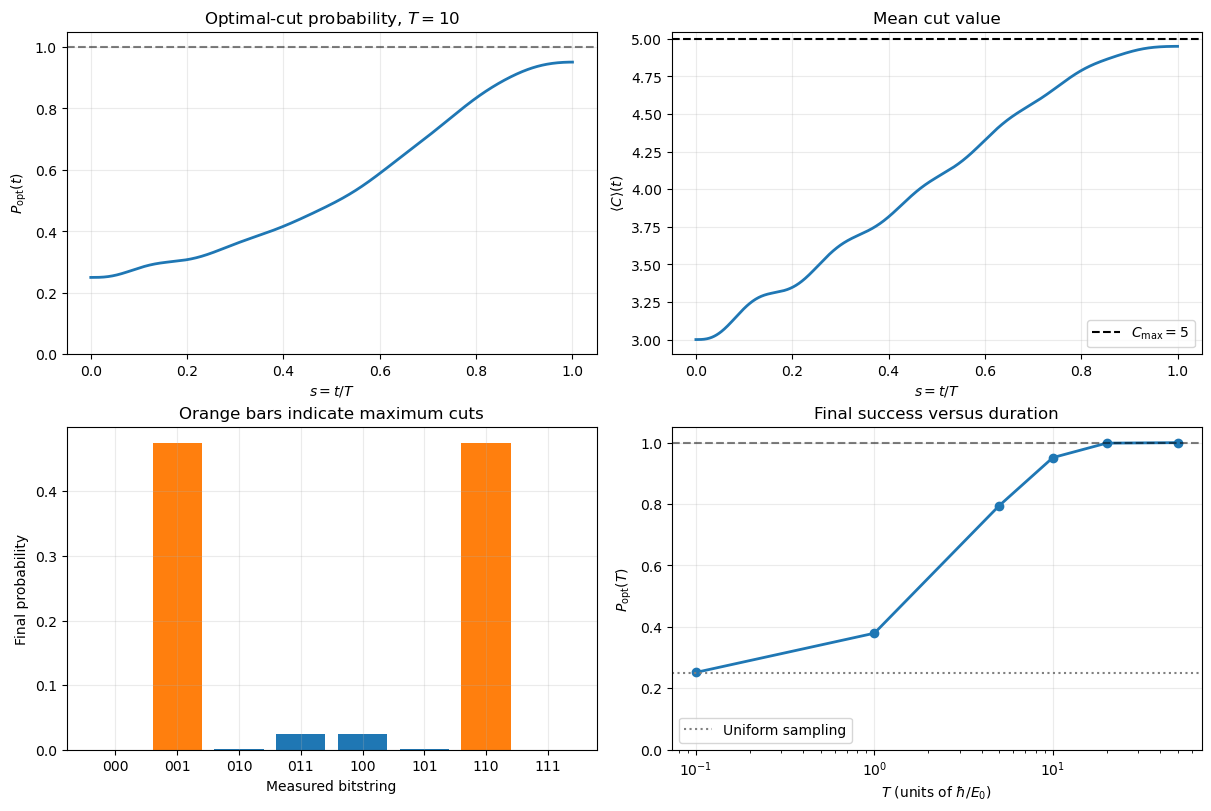

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ============================================================
# 1. Parameters and basis convention
# ============================================================
# Basis order: |000>, |001>, ..., |111>
# Spin 0 is the leftmost bit.
# Hamiltonian energies are measured in E0; times in hbar/E0.

N = 3
dim = 2**N

edges = [
    (0, 1, 1.0),
    (1, 2, 2.0),
    (0, 2, 3.0),
]

T_values = [0.1, 1.0, 5.0, 10.0, 20.0, 50.0]
T_plot = 10.0

s_grid = np.linspace(0.0, 1.0, 1001)
basis_labels = [format(n, f"0{N}b") for n in range(dim)]

# ============================================================
# 2. Spin operators
# ============================================================
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
I_full = np.eye(dim, dtype=complex)


def local_operator(operator, site):
    """Embed a single-spin operator in the N-spin Hilbert space."""
    result = np.array([[1.0]], dtype=complex)

    for j in range(N):
        result = np.kron(result, operator if j == site else I2)

    return result


X_ops = [local_operator(X, i) for i in range(N)]
Z_ops = [local_operator(Z, i) for i in range(N)]

# ============================================================
# 3. Cut operator and annealing Hamiltonians
# ============================================================
C_op = np.zeros((dim, dim), dtype=complex)

for i, j, weight in edges:
    C_op += 0.5 * weight * (I_full - Z_ops[i] @ Z_ops[j])

H_problem = -C_op
H_driver = -sum(X_ops)


def hamiltonian(s):
    """Linear interpolation from driver to problem Hamiltonian."""
    return (1.0 - s) * H_driver + s * H_problem


# Classical enumeration is used only to verify this small example.
cut_values = np.array([
    sum(
        weight
        for i, j, weight in edges
        if bits[i] != bits[j]
    )
    for bits in basis_labels
])

C_max = cut_values.max()
optimal_mask = np.isclose(cut_values, C_max)
optimal_labels = np.array(basis_labels)[optimal_mask]

assert np.allclose(np.diag(C_op).real, cut_values)
assert np.allclose(H_problem, H_problem.conj().T)

print("Classical verification")
for bits, cut in zip(basis_labels, cut_values):
    print(f"  {bits}: cut = {cut:.1f}")

print(f"\nMaximum cut: {C_max:.1f}")
print(f"Optimal bitstrings: {', '.join(optimal_labels)}")

# ============================================================
# 4. Initial state: ground state of H_driver
# ============================================================
psi_initial = np.ones(dim, dtype=complex) / np.sqrt(dim)

assert np.allclose(H_driver @ psi_initial, -N * psi_initial)

initial_probabilities = np.abs(psi_initial)**2

print(
    f"\nInitial P_opt = "
    f"{initial_probabilities[optimal_mask].sum():.6f}"
)
print(
    f"Initial mean cut = "
    f"{cut_values @ initial_probabilities:.6f}"
)

# ============================================================
# 5. Closed-system evolution
# ============================================================
def run_annealing(T):
    """
    Solve dpsi/ds = -i T H(s) psi on s in [0, 1].
    T is the dimensionless total annealing duration.
    """

    def rhs(s, psi):
        return -1j * T * (hamiltonian(s) @ psi)

    solution = solve_ivp(
        rhs,
        t_span=(0.0, 1.0),
        y0=psi_initial,
        t_eval=s_grid,
        method="DOP853",
        rtol=1e-10,
        atol=1e-12,
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    states = solution.y  # shape: (dim, number of time points)
    probabilities = np.abs(states)**2

    # Do not renormalize: retain normalization error as a diagnostic.
    norm = probabilities.sum(axis=0)
    P_opt = probabilities[optimal_mask].sum(axis=0)
    mean_cut = cut_values @ probabilities

    return {
        "T": T,
        "s": solution.t,
        "time": T * solution.t,
        "states": states,
        "probabilities": probabilities,
        "norm": norm,
        "P_opt": P_opt,
        "mean_cut": mean_cut,
        "norm_error": np.max(np.abs(norm - 1.0)),
    }


results = {T: run_annealing(T) for T in T_values}

print("\nFinal results")
print(f"{'T':>8} {'P_opt(T)':>14} {'Mean cut':>14} {'Max norm error':>18}")

for T, result in results.items():
    print(
        f"{T:8.1f}"
        f"{result['P_opt'][-1]:14.8f}"
        f"{result['mean_cut'][-1]:14.8f}"
        f"{result['norm_error']:18.2e}"
    )

# ============================================================
# 6. Plots
# ============================================================
selected = results[T_plot]

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    constrained_layout=True,
)

# (a) Probability of measuring a maximum cut
ax = axes[0, 0]
ax.plot(selected["s"], selected["P_opt"], lw=2)
ax.axhline(1.0, color="black", ls="--", alpha=0.5)
ax.set(
    xlabel=r"$s=t/T$",
    ylabel=r"$P_{\mathrm{opt}}(t)$",
    title=fr"Optimal-cut probability, $T={T_plot:g}$",
    ylim=(0, 1.05),
)

# (b) Expected cut value
ax = axes[0, 1]
ax.plot(selected["s"], selected["mean_cut"], lw=2)
ax.axhline(
    C_max,
    color="black",
    ls="--",
    label=fr"$C_{{\max}}={C_max:g}$",
)
ax.set(
    xlabel=r"$s=t/T$",
    ylabel=r"$\langle C\rangle(t)$",
    title="Mean cut value",
)
ax.legend()

# (c) Final measurement distribution
ax = axes[1, 0]
colors = [
    "tab:orange" if optimal else "tab:blue"
    for optimal in optimal_mask
]
ax.bar(
    basis_labels,
    selected["probabilities"][:, -1],
    color=colors,
)
ax.set(
    xlabel="Measured bitstring",
    ylabel="Final probability",
    title="Orange bars indicate maximum cuts",
)

# (d) Dependence on total annealing duration
ax = axes[1, 1]
durations = np.array(T_values)
final_success = np.array([
    results[T]["P_opt"][-1] for T in T_values
])

ax.semilogx(durations, final_success, "o-", lw=2)
ax.axhline(1.0, color="black", ls="--", alpha=0.5)
ax.axhline(
    optimal_mask.sum() / dim,
    color="gray",
    ls=":",
    label="Uniform sampling",
)
ax.set(
    xlabel=r"$T$ (units of $\hbar/E_0$)",
    ylabel=r"$P_{\mathrm{opt}}(T)$",
    title="Final success versus duration",
    ylim=(0, 1.05),
)
ax.legend()

for ax in axes.flat:
    ax.grid(alpha=0.25)

plt.show()